# CDS 3301 — C3 Clustering
## Mall Customers Dataset

**Student:** Hillary Wekesa  
**Registration:** CT204/119566/24 | **Group:** 13

**Allocated task:** Unsupervised K-Means clustering using numeric customer features only. Evaluate `k=2` through `k=8`, using `random_state=9522`.

This notebook is independent of the regression and classification notebooks. It requires only the Mall Customers CSV.

In [9]:
# If needed in a fresh environment, uncomment:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl requests

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 9522
TEST_SIZE = 0.25
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("Setup complete | random_state =", RANDOM_STATE, "| test_size =", TEST_SIZE)

Setup complete | random_state = 9522 | test_size = 0.25


## 1. Load the Mall Customers dataset

Upload or place the Mall Customers CSV (commonly named `Mall_Customers.csv`) beside this notebook.

In [10]:
from pathlib import Path
matches = list(Path.cwd().glob("*.csv"))
matches += list(Path("/content").glob("*.csv")) if Path("/content").exists() else []
mall_path = next((str(p) for p in matches if "mall" in p.name.lower() or "customer" in p.name.lower()), None)

if mall_path is None:
    try:
        from google.colab import files
        print("Upload the Mall Customers CSV.")
        uploaded = files.upload()
        mall_path = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    except ImportError:
        pass

if mall_path is None:
    raise FileNotFoundError("Place Mall_Customers.csv beside this notebook or upload it in Colab.")

df = pd.read_csv(mall_path)
df.columns = [str(c).strip() for c in df.columns]
display(df.head())
print("Shape:", df.shape)
print("Columns:", list(df.columns))

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Shape: (200, 5)
Columns: ['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


## 2. Inspect data and select numeric features

Exclude customer identifiers and any label/target column. The gender column is categorical and is not used because this assignment specifies numeric features only.

In [11]:
display(df.describe(include="all").T)
print("Missing values:")
display(df.isna().sum().to_frame("Missing values"))
print("Data types:")
display(df.dtypes.to_frame("dtype"))

exclude_tokens = ["id", "cluster", "label", "target", "segment", "class"]
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_cols = [
    col for col in numeric_cols
    if not any(token in col.lower() for token in exclude_tokens)
]
if len(feature_cols) < 2:
    raise ValueError(f"Need at least two numeric features after excluding IDs/labels. Found: {feature_cols}")

features = df[feature_cols].replace([np.inf, -np.inf], np.nan)
print("Numeric features used:", feature_cols)
print("Excluded columns:", [c for c in df.columns if c not in feature_cols])
display(features.head())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Genre,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


Missing values:


,Missing values
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


Data types:


,dtype
CustomerID,int64
Genre,str
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


Numeric features used: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Excluded columns: ['CustomerID', 'Genre']


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## 3. Standardise features

Median imputation handles any missing numeric feature values. Standardisation is important because K-Means uses distances, and variables with larger scales could otherwise dominate.

In [12]:
imputer = SimpleImputer(strategy="median")
features_imputed = imputer.fit_transform(features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_imputed)

print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (200, 3)


## 4. Run K-Means for k = 2 to 8

Compare the elbow curve (inertia) and silhouette scores. The final choice should be justified using both plots.

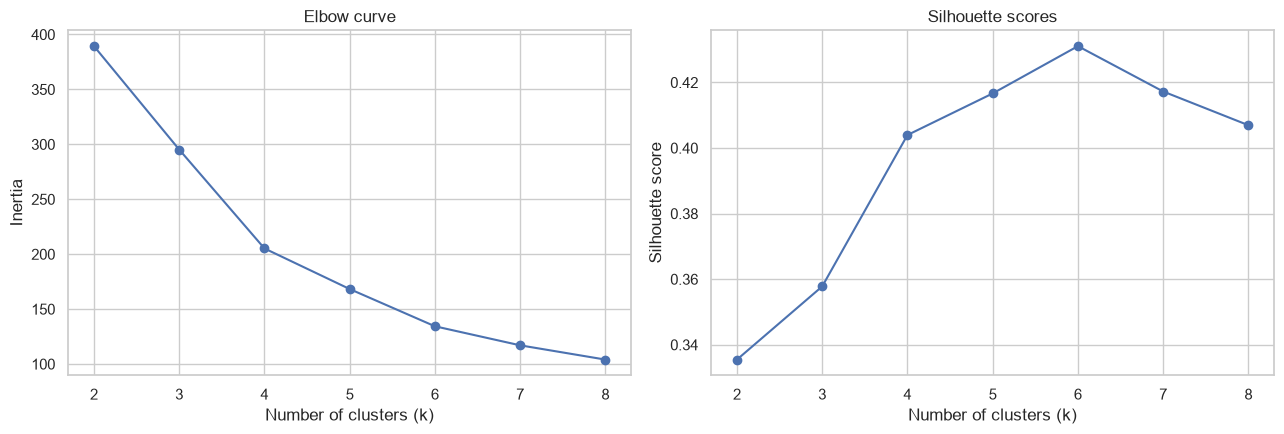

,Inertia,Silhouette score
k,,
2,389.3862,0.3355
3,295.2122,0.3578
4,205.2251,0.4040
5,168.2476,0.4166
6,134.3528,0.4311
7,117.0116,0.4172
8,104.0212,0.4069


Highest silhouette score at k = 6


In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = list(range(2, 9))
inertias, silhouettes = [], []
models, labels_by_k = {}, {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    models[k] = model
    labels_by_k[k] = labels
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_xticks(k_values)
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow curve")

axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_xticks(k_values)
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette scores")

plt.tight_layout()
plt.show()

evaluation = pd.DataFrame({"Inertia": inertias, "Silhouette score": silhouettes}, index=k_values)
evaluation.index.name = "k"
display(evaluation.round(4))
print("Highest silhouette score at k =", evaluation["Silhouette score"].idxmax())

## 5. Choose k and profile clusters

Inspect both plots, then change `CHOSEN_K` below to your justified value. The value 5 is only an initial placeholder.

In [14]:
CHOSEN_K = 5  # EDIT after reviewing elbow and silhouette plots.

if CHOSEN_K not in range(2, 9):
    raise ValueError("CHOSEN_K must be an integer from 2 through 8.")

final_model = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels = final_model.fit_predict(X_scaled)

profile_data = features.copy()
profile_data["Cluster"] = cluster_labels

print("Cluster sizes:")
display(profile_data["Cluster"].value_counts().sort_index().to_frame("Number of customers"))

print("Mean of each original feature by cluster:")
cluster_profile = profile_data.groupby("Cluster")[feature_cols].mean()
display(cluster_profile.round(2))

print("Median of each original feature by cluster:")
display(profile_data.groupby("Cluster")[feature_cols].median().round(2))

Cluster sizes:


,Number of customers
Cluster,
0,54
1,39
2,20
3,47
4,40


Mean of each original feature by cluster:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,25.19,41.09,62.24
1,39.87,86.10,19.36
2,46.25,26.75,18.35
3,55.64,54.38,48.85
4,32.88,86.10,81.53


Median of each original feature by cluster:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,24.0,40.0,58.0
1,41.0,78.0,17.0
2,47.0,26.5,14.5
3,54.0,54.0,48.0
4,32.0,78.5,83.0


## 6. PCA two-dimensional cluster visualisation

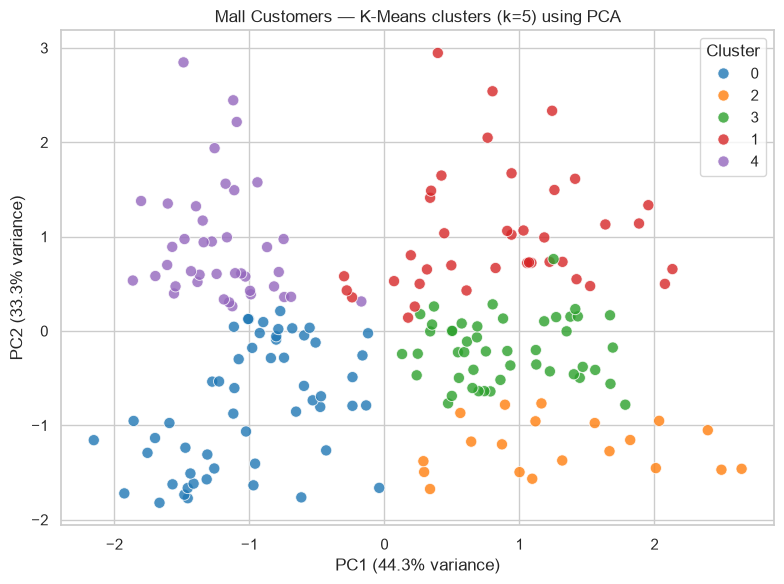

Variance explained by first two PCs: 0.7757


In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=65, alpha=0.8)
plt.title(f"Mall Customers — K-Means clusters (k={CHOSEN_K}) using PCA")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

print("Variance explained by first two PCs:", round(pca.explained_variance_ratio_.sum(), 4))

## 7. Describe each cluster in plain English

In [16]:
overall_means = features.mean(numeric_only=True)
print("Overall feature means:")
display(overall_means.to_frame("Overall mean").round(2))

print("Cluster means relative to overall means:")
display((cluster_profile - overall_means).round(2))

for cluster_id, row in cluster_profile.iterrows():
    count = int((cluster_labels == cluster_id).sum())
    print(f"Cluster {cluster_id} (n={count}):")
    for col in feature_cols:
        direction = "above" if row[col] > overall_means[col] else "below" if row[col] < overall_means[col] else "near"
        print(f"  {col}: {row[col]:.2f} ({direction} the overall mean of {overall_means[col]:.2f})")

Overall feature means:


,Overall mean
Age,38.85
Annual Income (k$),60.56
Spending Score (1-100),50.20


Cluster means relative to overall means:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,-13.66,-19.47,12.04
1,1.02,25.54,-30.84
2,7.40,-33.81,-31.85
3,16.79,-6.18,-1.35
4,-5.98,25.54,31.33


Cluster 0 (n=54):
  Age: 25.19 (below the overall mean of 38.85)
  Annual Income (k$): 41.09 (below the overall mean of 60.56)
  Spending Score (1-100): 62.24 (above the overall mean of 50.20)
Cluster 1 (n=39):
  Age: 39.87 (above the overall mean of 38.85)
  Annual Income (k$): 86.10 (above the overall mean of 60.56)
  Spending Score (1-100): 19.36 (below the overall mean of 50.20)
Cluster 2 (n=20):
  Age: 46.25 (above the overall mean of 38.85)
  Annual Income (k$): 26.75 (below the overall mean of 60.56)
  Spending Score (1-100): 18.35 (below the overall mean of 50.20)
Cluster 3 (n=47):
  Age: 55.64 (above the overall mean of 38.85)
  Annual Income (k$): 54.38 (below the overall mean of 60.56)
  Spending Score (1-100): 48.85 (below the overall mean of 50.20)
Cluster 4 (n=40):
  Age: 32.88 (below the overall mean of 38.85)
  Annual Income (k$): 86.10 (above the overall mean of 60.56)
  Spending Score (1-100): 81.53 (above the overall mean of 50.20)
